# Larger-than-Memory Detection and Tracking: Global 6-Hourly SST in a 32 GiB Job

This notebook measures what `compute_mode="streaming"` buys. The input is 6-hourly sea-surface temperature from the
EERIE IFS-FESOM2-SR control simulation on a 0.25° grid (721 x 1440 cells, 1971 onwards), and every run happens inside one
32 GiB batch job with a Dask cluster of 3 workers x 2 threads x 9 GB. The record length is the only thing that changes
between rungs. At 20 years the detect input is 121 GB of float32, 3.5 times the job's memory, and the tracker's int32 event
field is 91 GB, 2.65 times.

The rungs take one to three hours each, so they run as batch jobs and this notebook only reads their summaries. Each
summary records the job's peak memory as the kernel counts it, which is the number that decides whether a job is killed.

## Running a Rung

`ltm_run.py` runs one stage on the first `--years` of the record and writes `<label>.json` next to its output. Detect writes
the boolean extremes, and track reads them back from the detect rung of the same length:

```bash
sbatch --account=<project> ltm.sbatch detect --years 10 --workers 3 --threads 2 --memory-limit 9GB
sbatch --account=<project> ltm.sbatch track  --years 10 --workers 3 --threads 2 --memory-limit 9GB
SMOKE=1 python ltm_run.py detect --years 2   # plumbing check on one latitude band, minutes
```

Detection is a 5-year shifting baseline with an hour-of-year 95th percentile (`smooth_days=21`, `window_days=11`), so the
detect output starts five years into the record. A 10-year detect rung gives the tracker 5 years of extremes, and a
20-year rung gives it 15. The input is read in 40-step (10-day) chunks split into latitude bands of 103 rows. The tracker runs
with merging and splitting, `R_fill=12`, `T_fill=16` and a 600-cell area filter.

Memory comes from the job's control group (cgroup v2), sampled every 2 s. **Anon** is the memory the job's processes hold,
summed over the client, the workers and everything else in the job. The page cache is reported separately and not counted:
reading a store larger than memory fills the cache to the limit whatever the code does, and the kernel reclaims it on
demand. Dask spills to disk with its default thresholds.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

runs = json.loads(Path("ltm_results.json").read_text())["runs"]
GiB = 2**30
job = runs[0]["job_memory_bytes"]

table = pd.DataFrame(
    {
        "stage": r["stage"],
        "mode": r["mode"],
        "years": r["years"],
        "outcome": r["outcome"],
        "data (GB)": r["data_bytes"] / 1e9,
        "data / job": r["data_bytes"] / job,
        "peak anon (GiB)": r["peak_anon_bytes"] / GiB if r["peak_anon_bytes"] else float("nan"),
        "spilled (GB)": r["peak_spilled_gb"],
        "wall (min)": r["wall_s"] / 60,
        "OOM kills": r["oom_kills"],
    }
    for r in runs
)
table.round(2)

,stage,mode,years,outcome,data (GB),data / job,peak anon (GiB),spilled (GB),wall (min),OOM kills
0,detect,streaming,10,completed,60.68,1.77,19.41,46.34,63.24,0
1,detect,streaming,20,completed,121.35,3.53,20.63,137.81,166.41,0
2,detect,persist,10,completed,60.68,1.77,20.10,54.86,68.76,0
3,detect,persist,20,completed,121.35,3.53,21.48,161.24,191.50,0
4,track,streaming,10,completed,30.35,0.88,9.35,0.00,56.54,0
5,track,streaming,20,completed,91.02,2.65,9.42,0.00,138.61,0
6,track,persist,20,oom_killed,91.02,2.65,NaN,1.80,86.20,1


`data` is the float32 input for detect and the int32 event field for track, both uncompressed. Every `streaming` rung and
both `persist` detect rungs completed with no kernel OOM kill. The 20-year `persist` track was killed by the kernel, so it
has no memory series and no peak anon.

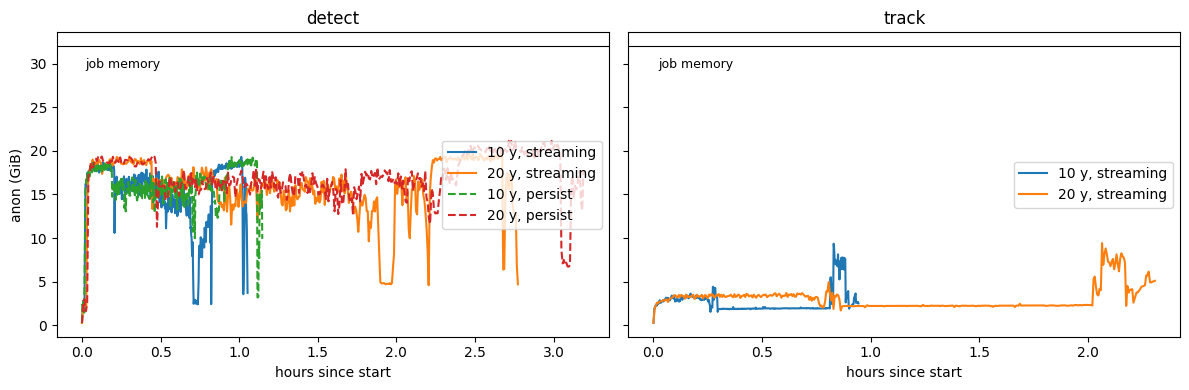

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, stage in zip(axes, ["detect", "track"]):
    for r in (r for r in runs if r["stage"] == stage and r["anon_series"]):
        t, anon = zip(*r["anon_series"])
        style = "-" if r["mode"] == "streaming" else "--"
        ax.plot([s / 3600 for s in t], [a / GiB for a in anon], style, label=f"{r['years']} y, {r['mode']}")
    ax.axhline(job / GiB, color="k", lw=0.8)
    ax.text(0.02, job / GiB - 2.5, "job memory", fontsize=9)
    ax.set_title(stage)
    ax.set_xlabel("hours since start")
    ax.legend(loc="center right")
axes[0].set_ylabel("anon (GiB)")
fig.tight_layout()

## Memory Is Flat in Record Length

Doubling the detect record from 10 to 20 years doubles the input (61 to 121 GB) and raises the peak anon by 6 %, from
19.4 to 20.6 GiB. The tracker's peak is flatter still: tripling the event field (30 to 91 GB) moves it by under 1 %, to 9.4 GiB. In
both stages the record length shows up in the wall time and in the bytes Dask spills to disk (46 GB at 10 years and 138 GB
at 20 for detect), while the peak stays where the cluster and the chunking put it.

The wall time grows faster than the record. The 20-year detect took 2.6 times as long as the 10-year one for twice the input,
and the 20-year track 2.5 times as long for three times the field. The longer track also found 6,557 events against
2,879, and 91,108 merges against 45,028.

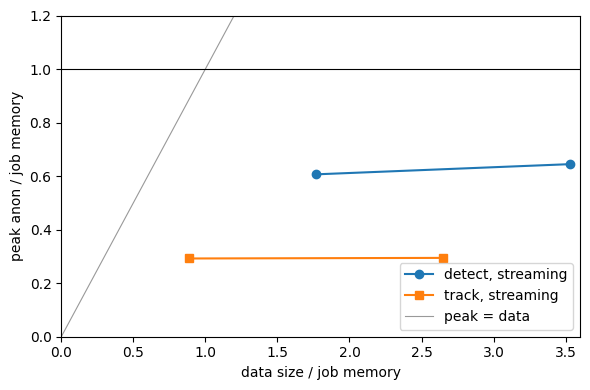

In [3]:
fig, ax = plt.subplots(figsize=(6, 4))
for stage, marker in [("detect", "o"), ("track", "s")]:
    sel = table[(table.stage == stage) & (table["mode"] == "streaming")]
    ax.plot(sel["data / job"], sel["peak anon (GiB)"] * GiB / job, marker=marker, label=f"{stage}, streaming")
ax.plot([0, 3.6], [0, 3.6], color="0.6", lw=0.8, label="peak = data")
ax.axhline(1, color="k", lw=0.8)
ax.set_xlabel("data size / job memory")
ax.set_ylabel("peak anon / job memory")
ax.set_xlim(0, 3.6)
ax.set_ylim(0, 1.2)
ax.legend()
fig.tight_layout()

## The `persist` Reference

`persist` keeps the anomaly, the extremes and the tracker's intermediate fields in worker memory, where `streaming` writes
them to a Zarr staging directory and reads them back. In this job the workers spill to disk once past Dask's memory
threshold, so pinned data does not by itself push a run past the job's memory.

`persist` detect completed at both lengths in the same job and on the same cluster, and found the same extreme cell-steps
as `streaming` (174,512,355 at 10 years, 691,300,047 at 20). Pinning the data cost spill and wall time: at 20 years `persist`
spilled 161 GB against 138, ran 192 minutes against 166, and peaked at 21.5 GiB anon against 20.6. On this cluster both
modes finish detection, and `streaming` is the faster.

The tracker behaves differently. The 20-year `persist` track was killed by the kernel after 86 minutes, 90 of 548 merge
chunks in. The workers stayed inside their 9 GB limits (5.2 to 6.9 GB each in the last samples, with no nanny memory warning), while the
client's memory climbed from under 1 GB to 14.6 GB over the run's last half hour, until the job reached its 32 GiB limit.
The `streaming` track of the same field never held more than 3 GB on the client and completed in 139 minutes. This is a
single run, and why the client grows under `persist` is not established.

## Adapting the Ladder

- `--memory-limit` is passed to the cluster and checked: Dask sizes a local cluster from the machine's memory, not the batch
  job's, so without it the memory limit never binds. `ltm_run.py` writes the limit the workers report into the summary.
- 3 workers x 9 GB leaves about 7 GiB of the 32 GiB for the client, which runs the tracker's merge loop.
- Staging and spill need disk: at 20 years detect spilled 138 GB with `streaming` and 161 GB with `persist`. Point `MAREX_SCRATCH` at a file system with room.
- `--stall-minutes N` stops a run whose scheduler makes no progress for N minutes and records it as `stalled`. Leave it at 0
  for the tracker, whose merge loop runs on the client for long stretches with no scheduler activity.